# 02 - From prototype to the final deep SNN

The development path of the two-layer convolutional SNN described in thesis section 4.5:

| Step | Encoder (layer 1) | Readout (layer 2) | Learning in layer 2 |
|---|---|---|---|
| 1 | PyTorch conv-LIF with WTA, Hebbian | linear layer | backprop (Adam) |
| 2 | NumPy, Hebbian + WTA | 10 neurons | delta rule (softmax error) |
| 3 | NumPy, STDP + WTA (**final**) | 10 neurons | **R-STDP** (local, reward-modulated) |

Step 4 applies the final model as a sliding-window detector. Steps 1 and 2 are kept as
ablations: they show what a non-local readout buys in accuracy.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # make the snn_detection package importable

import numpy as np
import matplotlib.pyplot as plt

import time
import torch
import torch.nn as nn
import torch.nn.functional as F

from snn_detection.data import load_mnist
from snn_detection.deep_snn import extract_patches, train_deep_snn, evaluate
from snn_detection.detection import detect_digits, evaluate_detections, make_fixed_canvas, non_max_suppression
from snn_detection.visualization import draw_detections, plot_filters

np.random.seed(0)
torch.manual_seed(0)
x_train, y_train, x_test, y_test = load_mnist()  # floats in [0, 1]

## Step 1 - PyTorch prototype (Hebbian encoder + backprop readout)

Phase 1 learns 16 filters with a Hebbian rule computed by an "autograd trick": the
gradient of `sum(conv(input) * output_spikes)` with respect to the weights is exactly the
input x output-spike correlation. After each update the filters are renormalised to a fixed
total weight (homeostasis). Phase 2 freezes the encoder and trains a linear readout with Adam.

In [2]:
class WTAConvLayer(nn.Module):
    """Conv-LIF layer with hard winner-take-all across filters at each location."""

    def __init__(self, n_filters=16, k=5, v_th=2.0, decay=0.5):
        super().__init__()
        self.weights = nn.Parameter(torch.rand(n_filters, 1, k, k) + 0.1)
        self.v_th, self.decay = v_th, decay
        self.volt = None
        self.normalize_weights()

    def normalize_weights(self):
        with torch.no_grad():
            w_sum = self.weights.sum(dim=(1, 2, 3), keepdim=True)
            w_sum[w_sum == 0] = 1.0
            self.weights.data = (self.weights.data / w_sum * 5.0).clamp(0.0, 1.0)

    def forward(self, x):
        if self.volt is None:
            self.volt = torch.zeros(x.shape[0], self.weights.shape[0], x.shape[2] - 4, x.shape[3] - 4)
        self.volt = self.volt * self.decay + F.conv2d(x, self.weights)
        spikes = ((self.volt == self.volt.max(dim=1, keepdim=True)[0]) & (self.volt >= self.v_th)).float()
        self.volt = self.volt * (1 - spikes)
        return spikes


encoder = WTAConvLayer()
readout = nn.Linear(16 * 24 * 24, 10)
x_tr = torch.tensor(x_train, dtype=torch.float32).unsqueeze(1)
x_te = torch.tensor(x_test, dtype=torch.float32).unsqueeze(1)
y_tr, y_te = torch.tensor(y_train), torch.tensor(y_test)

# Phase 1: Hebbian filter learning on 101 batches of 64 rate-coded images.
order = torch.randperm(len(x_tr))
for b in range(101):
    data = x_tr[order[b * 64:(b + 1) * 64]]
    encoder.volt = None
    spikes_in = (torch.rand_like(data) < data).float()
    spikes_out = encoder(spikes_in)
    pseudo_loss = (F.conv2d(spikes_in, encoder.weights) * spikes_out.detach()).sum()
    grad = torch.autograd.grad(pseudo_loss, encoder.weights)[0]
    with torch.no_grad():
        encoder.weights += 0.05 * grad / 64
        encoder.normalize_weights()
encoder.weights.requires_grad_(False)


def features(x):
    encoder.volt = None
    return encoder((x > 0.5).float()).flatten(1)  # binarised input, single step


# Phase 2: supervised readout with backprop.
optimizer = torch.optim.Adam(readout.parameters(), lr=0.01)
for epoch in range(3):
    order = torch.randperm(len(x_tr))
    for b in range(0, len(order), 64):
        idx = order[b:b + 64]
        loss = F.cross_entropy(readout(features(x_tr[idx])), y_tr[idx])
        optimizer.zero_grad(); loss.backward(); optimizer.step()
    print(f"epoch {epoch}: last batch loss {loss.item():.4f}")

with torch.no_grad():
    predictions = torch.cat([readout(features(x_te[i:i + 1000])).argmax(1) for i in range(0, len(x_te), 1000)])
    accuracy = (predictions == y_te).float().mean().item()
print(f"Test accuracy (10,000 images): {accuracy * 100:.2f}%")

epoch 0: last batch loss 0.0427


epoch 1: last batch loss 0.2020


epoch 2: last batch loss 0.0004


Test accuracy (10,000 images): 96.52%


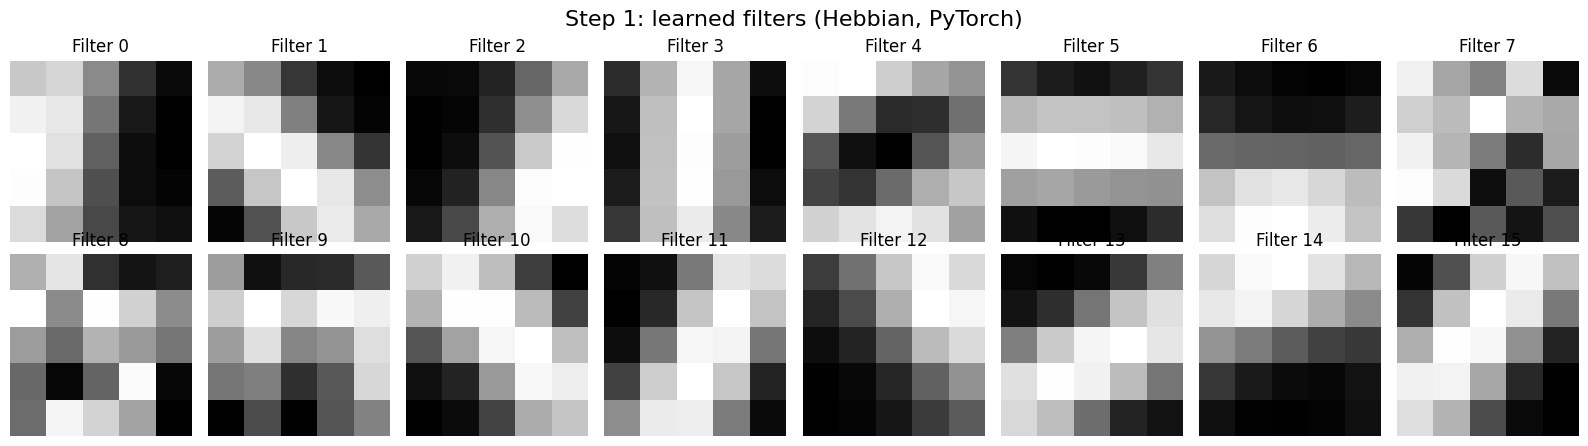

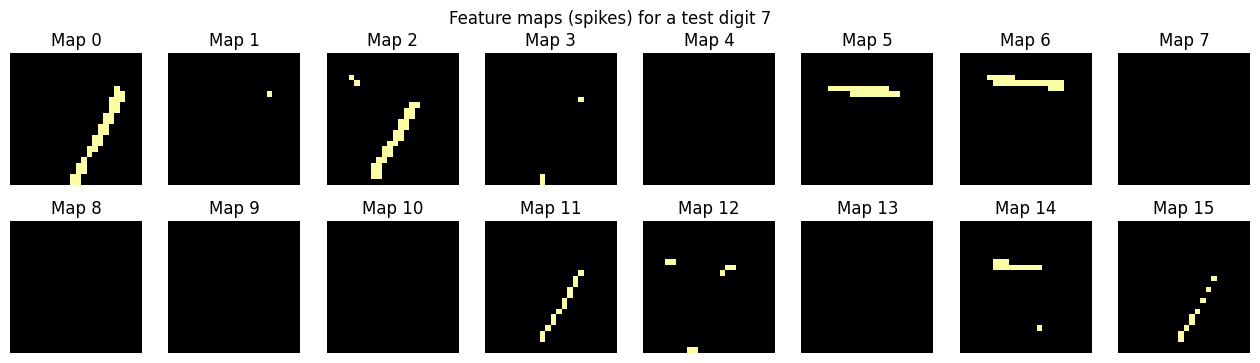

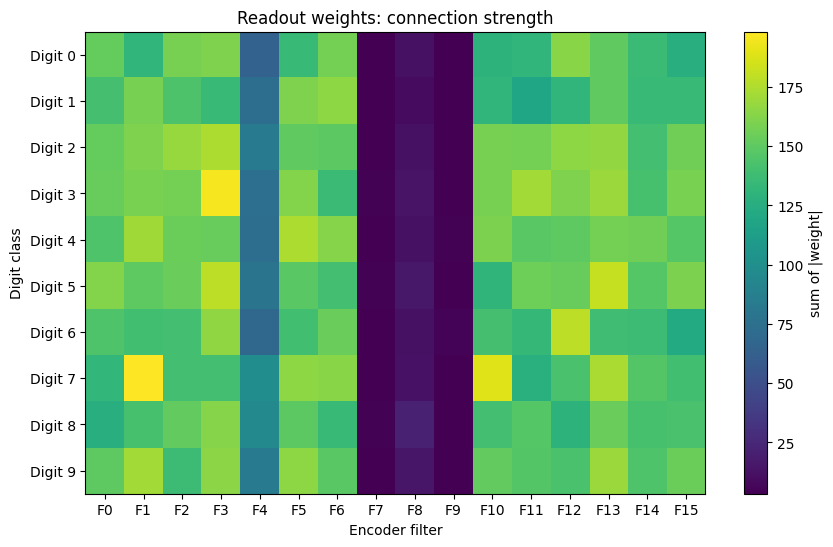

In [3]:
filters = encoder.weights.detach()[:, 0]
plot_filters(((filters - filters.min()) / (filters.max() - filters.min())).reshape(16, 25).numpy(),
             title="Step 1: learned filters (Hebbian, PyTorch)")
plt.show()

maps = features(x_te[:1]).reshape(16, 24, 24)
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
fig.suptitle(f"Feature maps (spikes) for a test digit {y_test[0]}")
for i, ax in enumerate(axes.flat):
    ax.imshow(maps[i], cmap="inferno"); ax.set_title(f"Map {i}"); ax.axis("off")
plt.show()

strength = readout.weight.detach().reshape(10, 16, 24, 24).abs().sum(dim=(2, 3))
plt.figure(figsize=(10, 6))
plt.imshow(strength, cmap="viridis", aspect="auto")
plt.xticks(range(16), [f"F{i}" for i in range(16)]); plt.yticks(range(10), [f"Digit {i}" for i in range(10)])
plt.xlabel("Encoder filter"); plt.ylabel("Digit class"); plt.title("Readout weights: connection strength")
plt.colorbar(label="sum of |weight|"); plt.show()

## Step 2 - Pure NumPy with a delta-rule readout

The encoder moves to NumPy (single-step WTA, Hebbian update without the constant decay of
the final version). The readout uses a softmax error signal, i.e. a delta rule: still a
supervised error-driven rule rather than a spike-timing rule.

In [4]:
from snn_detection.deep_snn import STDPEncoder


class HebbianEncoder(STDPEncoder):
    """Step-2 variant: weights += 0.05 * normalised coincidences (no decay term)."""

    def forward(self, image, learn=False):
        patches = extract_patches(image, self.k)
        voltages = self.weights @ patches.T
        spikes = ((voltages == voltages.max(axis=0)) & (voltages >= self.threshold)).astype(float)
        if learn:
            dw = spikes @ patches
            if dw.max() > 0:
                self.weights += 0.05 * (dw / dw.max())
                self.normalize_weights()
        return spikes


def softmax(z):
    e = np.exp(z - z.max())
    return e / e.sum()


hebb = HebbianEncoder()
for i in range(2000):
    hebb.forward(x_train[i], learn=True)

w_out = np.random.randn(10, 16 * 576) * 0.01
history = []
for i in range(2000, 22000):
    x = hebb.forward(x_train[i]).ravel()
    probs = softmax(w_out @ x)
    history.append(np.argmax(probs) == y_train[i])
    w_out += 0.005 * np.outer(np.eye(10)[y_train[i]] - probs, x)

test_acc = np.mean([np.argmax(w_out @ hebb.forward(x_test[i]).ravel()) == y_test[i] for i in range(1000)])
print(f"training accuracy over the last 1000 steps: {np.mean(history[-1000:]) * 100:.2f}%")
print(f"test accuracy (1000 images): {test_acc * 100:.2f}%")

training accuracy over the last 1000 steps: 96.60%
test accuracy (1000 images): 94.40%


## Step 3 - Final model: STDP encoder + R-STDP readout

Only local learning rules: unsupervised STDP for the filters and reward-modulated STDP for
the readout. This is exactly what `python scripts/train_deep_snn.py` runs.

Phase 1: unsupervised STDP on 1000 images...
Phase 2: supervised R-STDP on 10000 images (encoder frozen)...


  step 1000/10000 | accuracy on last 500: 87.20%
  step 2000/10000 | accuracy on last 500: 94.00%


  step 3000/10000 | accuracy on last 500: 94.00%
  step 4000/10000 | accuracy on last 500: 94.80%


  step 5000/10000 | accuracy on last 500: 92.20%
  step 6000/10000 | accuracy on last 500: 93.60%


  step 7000/10000 | accuracy on last 500: 95.20%
  step 8000/10000 | accuracy on last 500: 94.40%


  step 9000/10000 | accuracy on last 500: 92.00%
training time: 1.3s


test accuracy (1000 images): 91.40%


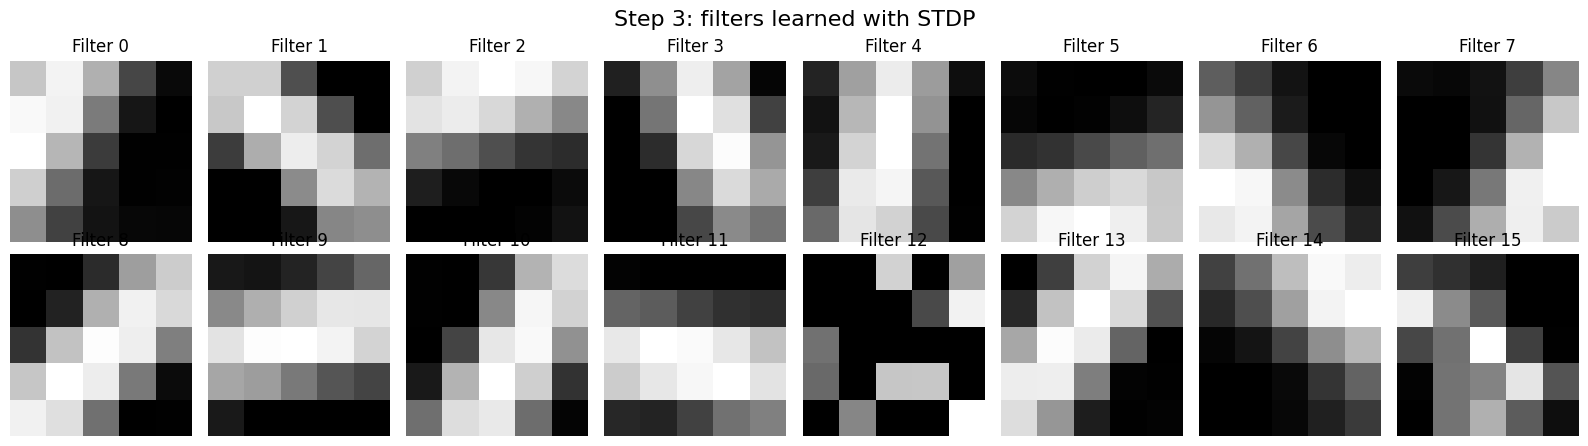

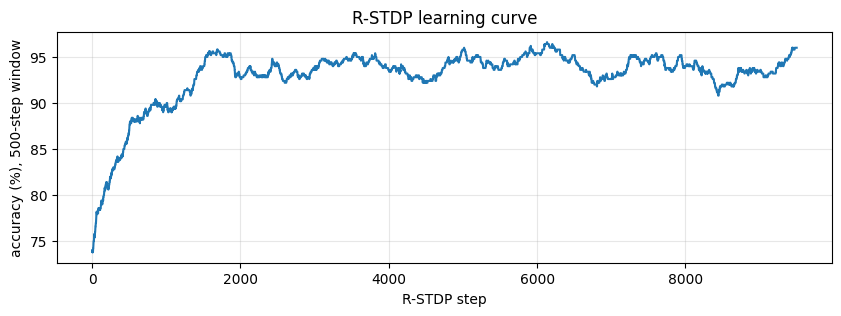

In [5]:
start = time.time()
encoder, classifier, history = train_deep_snn(x_train, y_train, n_stdp=1000, n_rstdp=10000)
print(f"training time: {time.time() - start:.1f}s")
print(f"test accuracy (1000 images): {evaluate(encoder, classifier, x_test[:1000], y_test[:1000]) * 100:.2f}%")

plot_filters(encoder.weights, title="Step 3: filters learned with STDP")
plt.show()

plt.figure(figsize=(10, 3))
plt.plot(np.convolve(history, np.ones(500) / 500, mode="valid") * 100)
plt.xlabel("R-STDP step"); plt.ylabel("accuracy (%), 500-step window"); plt.title("R-STDP learning curve")
plt.grid(alpha=0.3); plt.show()

## Step 4 - Sliding-window detection

A 28x28 window slides over a 100x100 canvas with stride 2. A window becomes a detection if
the winning output voltage reaches 93 and no bright pixel touches its 2-pixel border
(the boundary constraint against off-centre crops). IoU-based NMS then keeps one box per digit.
An earlier version (score threshold 6, NMS overlap 0.1, model trained on 500/2000 images,
no boundary constraint) is superseded by this one.

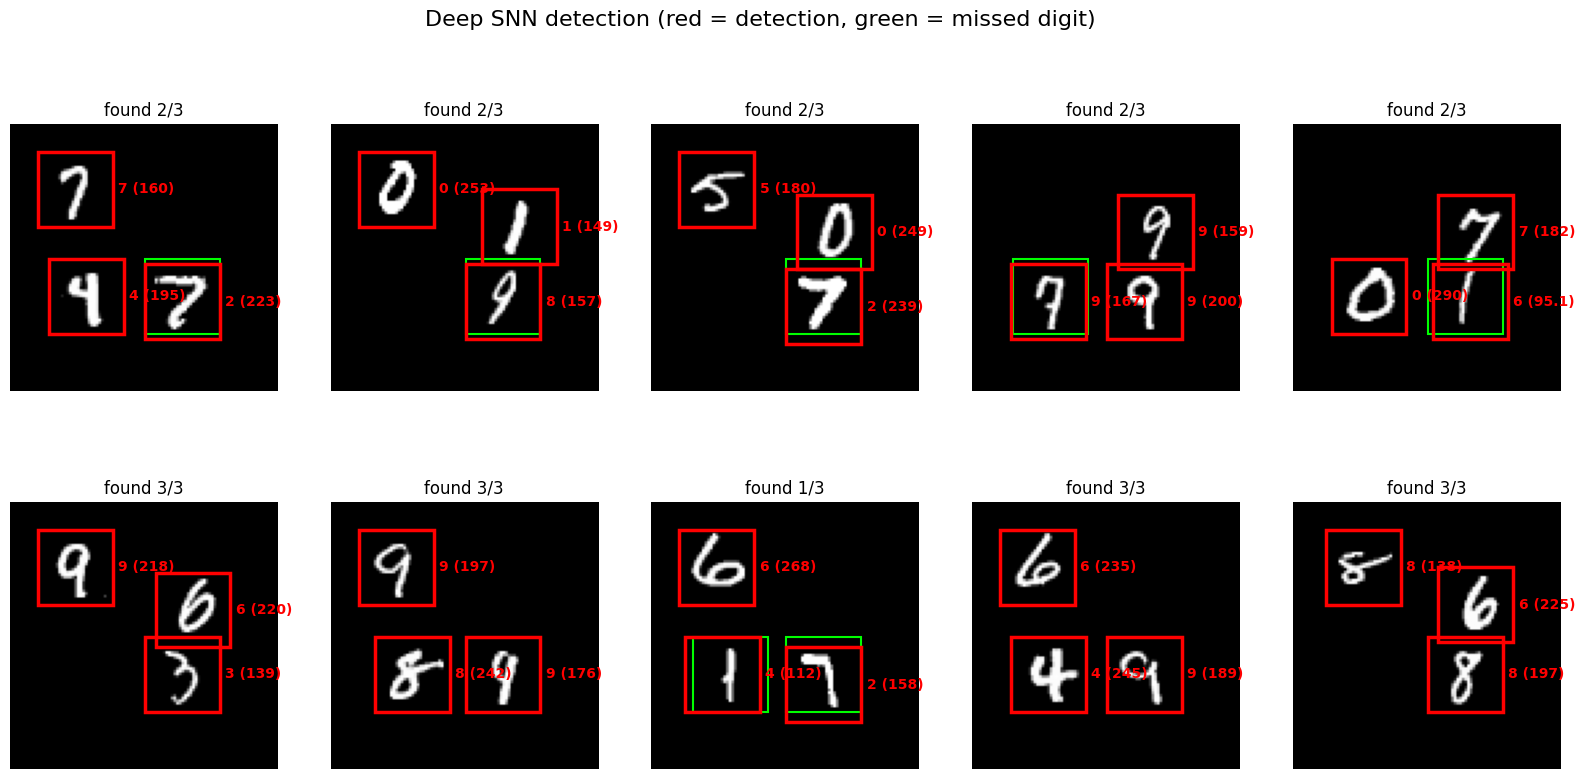

found 23/30 digits, 7 false positives


In [6]:
fig, axes = plt.subplots(2, 5, figsize=(20, 9))
found = total = false_pos = 0
for ax in axes.flat:
    canvas, truths = make_fixed_canvas(x_test, y_test, num_digits=3)
    detections = non_max_suppression(detect_digits(canvas, encoder, classifier), threshold=0.3)
    result = evaluate_detections(detections, truths)
    found += len(result["found"]); total += len(truths); false_pos += len(result["false_positives"])
    draw_detections(ax, canvas, detections, [truths[g] for g in result["missed"]],
                    title=f"found {len(result['found'])}/{len(truths)}")
fig.suptitle("Deep SNN detection (red = detection, green = missed digit)", fontsize=16)
plt.show()
print(f"found {found}/{total} digits, {false_pos} false positives")